# 05 — Improving accuracy on the unseen Misinfo dataset
**KhabarNazar — Image Analysis Module**

The final ResNet18 from notebook 03 scores **73% on Misinfo**: it catches 88% of the fakes but accepts only 58% of the
real photos. Its main problem is **false alarms on real photos from an unfamiliar source (domain shift)**.

### Rules that keep the results honest
- Misinfo is split once (stratified by generator and class) into **ADAPT (20%)** and **TEST (80%)**.
  **Every method is scored on the same TEST 80%**, so the numbers are comparable.
- **Zero-shot methods (sections 2–5) never see any Misinfo image** — not for training, not for choosing settings,
  not for choosing the threshold. Their threshold is fixed at 0.5 and settings are chosen on a validation split of
  the *training* datasets.
- **Section 6 (few-shot adaptation)** trains with the ADAPT 20%. Its result must be reported as
  *"adapted with 20% of Misinfo"*, not as unseen.

| Section | Approach | Uses Misinfo for training? |
|---|---|---|
| 1 | Diagnosis of the current model (could a better threshold alone fix it?) | No |
| 2–3 | **Foundation models** (CLIP ViT-L/14, DINOv2-L) as frozen feature extractors + a small classifier | No |
| 4 | **ResNet18 retrained with robustness augmentation** (resize, JPEG, blur) | No |
| 5 | **Ensemble** of the zero-shot models | No |
| 6 | **Few-shot adaptation** with 20% of Misinfo | **Yes (20%)** |

References: Pelekh (2025) found foundation models (DINOv2) generalise better than CNNs to unseen generators;
Ojha et al. (2023, *UnivFD*, CVPR) showed the same for CLIP ViT-L/14 features with a simple linear classifier.

**Before running:** `pip install transformers` (one time). The first run downloads CLIP (~1.7 GB) and DINOv2 (~1.2 GB).
Expected run time on the RTX A4000: about **1–1.5 hours** (feature extraction ~10–20 min per model, ResNet retraining ~30–45 min).
Extracted features are cached in `data/features/`, so re-running is fast.

In [1]:
import json, time, random, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import joblib

from khabar_aug import RandomRescale, RandomJPEG     # helper file next to this notebook

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
FEAT = ROOT / "data" / "features"; FEAT.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"
OUTPUTS = ROOT / "outputs"; OUTPUTS.mkdir(exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

BATCH_SIZE = 64
WORKERS = 4                  # set to 0 if a progress bar ever freezes at 0%
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLIP_MEAN, CLIP_STD = [0.4815, 0.4578, 0.4082], [0.2686, 0.2613, 0.2758]
CLASSES = ["fake", "real"]

GPU: NVIDIA RTX A4000


## 0. Data, the Misinfo split and the scoring function

In [2]:
SETS = {   # key: (folder, preparation mode)
    "aivr_train": (P / "ai_vs_real" / "train", "crop"),
    "tiny_train": (P / "tiny_genimage" / "train", "tiny"),
    "aivr_test":  (P / "ai_vs_real" / "test", "crop"),
    "tiny_val":   (P / "tiny_genimage" / "val", "tiny"),
    "misinfo":    (P / "misinfo" / "test", "crop"),
}
TRAIN_KEYS = ["aivr_train", "tiny_train"]

def group_of(path):
    return Path(path).name.split("_")[0]      # generator name stored in the file name (notebook 01)

BASE = {k: datasets.ImageFolder(f) for k, (f, _) in SETS.items()}
for ds in BASE.values():
    assert ds.classes == CLASSES, ds.classes
LABELS = {k: np.array(ds.targets) for k, ds in BASE.items()}
GROUPS = {k: np.array([group_of(p) for p, _ in ds.samples]) for k, ds in BASE.items()}
for k in SETS:
    print(f"{k:11s} {len(LABELS[k]):6d} images")

# Misinfo: ADAPT 20% / TEST 80%, stratified by generator and class (fixed seed)
rng = np.random.RandomState(SEED)
adapt = []
for g in np.unique(GROUPS["misinfo"]):
    for c in (0, 1):
        idx = np.where((GROUPS["misinfo"] == g) & (LABELS["misinfo"] == c))[0]
        adapt += list(rng.choice(idx, len(idx) // 5, replace=False))
MIS_ADAPT = np.sort(np.array(adapt))
MIS_TEST = np.setdiff1d(np.arange(len(LABELS["misinfo"])), MIS_ADAPT)
print(f"\nMisinfo ADAPT {len(MIS_ADAPT)} | TEST {len(MIS_TEST)}")
display(pd.crosstab(GROUPS["misinfo"][MIS_TEST], np.array(CLASSES)[LABELS["misinfo"][MIS_TEST]]))

aivr_train   48000 images
tiny_train   28000 images
aivr_test    12000 images
tiny_val      7000 images
misinfo       8000 images

Misinfo ADAPT 1600 | TEST 6400


col_0,fake,real
row_0,,
FLUX1-dev,800,800
PixArt-XL-2-1024-MS,800,800
SDXL1,800,800
imagen3,800,800


In [3]:
RESULTS, PROBS = [], {}
EVAL = {"AI vs Real": ("aivr_test", None), "Tiny-GenImage": ("tiny_val", None), "Misinfo TEST": ("misinfo", MIS_TEST)}

def score(name, probs):
    # probs: {set key -> probability of REAL for every image of that set}. Threshold fixed at 0.5.
    row = {"method": name}
    for label, (k, idx) in EVAL.items():
        p, y = probs[k], LABELS[k]
        if idx is not None:
            p, y = p[idx], y[idx]
        row[f"{label} acc"] = accuracy_score(y, (p >= 0.5).astype(int))
        row[f"{label} AUC"] = roc_auc_score(y, p)
    p, y = probs["misinfo"][MIS_TEST], LABELS["misinfo"][MIS_TEST]
    row["Misinfo fakes caught"] = ((p < 0.5) & (y == 0)).sum() / (y == 0).sum()
    row["Misinfo reals accepted"] = ((p >= 0.5) & (y == 1)).sum() / (y == 1).sum()
    RESULTS[:] = [r for r in RESULTS if r["method"] != name] + [row]
    PROBS[name] = probs
    return pd.DataFrame([row]).set_index("method").round(4)

def misinfo_per_generator(name):
    p, y, g = PROBS[name]["misinfo"][MIS_TEST], LABELS["misinfo"][MIS_TEST], GROUPS["misinfo"][MIS_TEST]
    df = pd.DataFrame({"generator": g, "class": np.array(CLASSES)[y], "correct": (p >= 0.5).astype(int) == y})
    t = df.pivot_table(index="generator", columns="class", values="correct", aggfunc="mean")
    t.columns = ["fakes caught", "reals accepted"]
    return t.round(3)

## 1. Diagnosis: the current final model (ResNet18, Stage 2)
The histogram shows the model's P(real) for Misinfo's real and fake images. The threshold curve shows what accuracy
would be at *every* threshold. The best point on that curve is chosen by looking at the test answers, so it is
**an upper bound for diagnosis only — not a valid result**. It tells us whether moving the threshold alone could
ever reach 90%.

In [4]:
def eval_tf(mode, mean, std):
    pre = [transforms.Resize(256)] if mode == "tiny" else []
    return transforms.Compose(pre + [transforms.CenterCrop(224), transforms.ToTensor(), transforms.Normalize(mean, std)])

def eval_loader(key, mean, std, bs=128):
    folder, mode = SETS[key]
    return DataLoader(datasets.ImageFolder(folder, eval_tf(mode, mean, std)), batch_size=bs, shuffle=False,
                      num_workers=WORKERS, pin_memory=True)

def load_resnet(name):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(m.fc.in_features, 2)
    m.load_state_dict(torch.load(MODELS / name, map_location="cpu", weights_only=True))
    return m.to(device).eval()

@torch.no_grad()
def resnet_probs(model, keys=("aivr_test", "tiny_val", "misinfo")):
    out = {}
    for k in keys:
        ps = []
        for x, _ in tqdm(eval_loader(k, IMAGENET_MEAN, IMAGENET_STD), desc=k, leave=False):
            with torch.amp.autocast("cuda"):
                ps.append(torch.softmax(model(x.to(device)), 1)[:, 1].float().cpu())
        out[k] = torch.cat(ps).numpy()
    return out

stage2 = load_resnet("resnet18_final.pth")
display(score("ResNet18 Stage 2 (current)", resnet_probs(stage2)))
del stage2; torch.cuda.empty_cache()

aivr_test:   0%|          | 0/94 [00:08<?, ?it/s]

tiny_val:   0%|          | 0/55 [00:07<?, ?it/s]

misinfo:   0%|          | 0/63 [00:10<?, ?it/s]

,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
ResNet18 Stage 2 (current),0.9383,0.9854,0.9199,0.9757,0.7316,0.8622,0.8806,0.5825


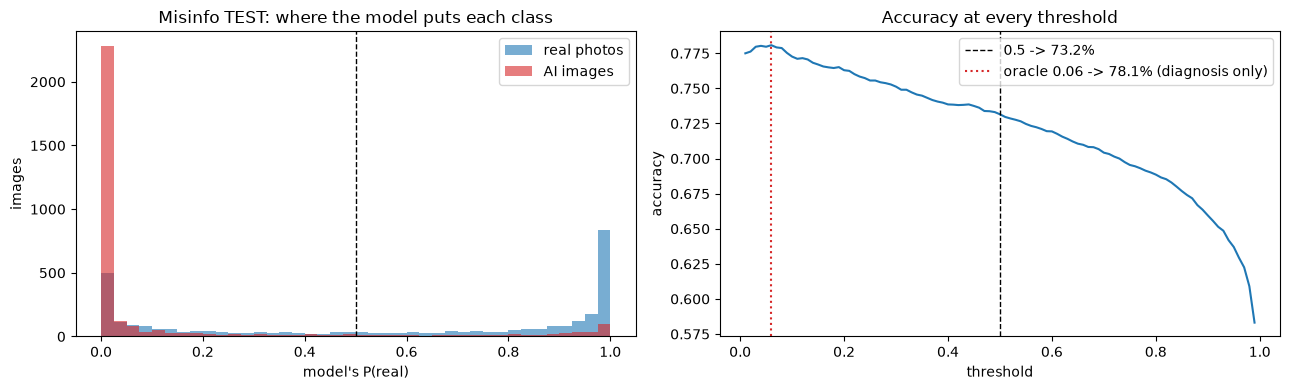

Even the best possible threshold gives 78.1% -> the threshold alone cannot reach 90%; the model's features need to separate real and fake better.


In [5]:
p = PROBS["ResNet18 Stage 2 (current)"]["misinfo"][MIS_TEST]
y = LABELS["misinfo"][MIS_TEST]
ths = np.linspace(0.01, 0.99, 99)
accs = [accuracy_score(y, (p >= t).astype(int)) for t in ths]
best_t = ths[int(np.argmax(accs))]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.hist(p[y == 1], bins=40, alpha=0.6, label="real photos", color="tab:blue")
a1.hist(p[y == 0], bins=40, alpha=0.6, label="AI images", color="tab:red")
a1.axvline(0.5, color="k", ls="--", lw=1); a1.set_xlabel("model's P(real)"); a1.set_ylabel("images")
a1.set_title("Misinfo TEST: where the model puts each class"); a1.legend()
a2.plot(ths, accs); a2.axvline(0.5, color="k", ls="--", lw=1, label=f"0.5 -> {accs[49]:.1%}")
a2.axvline(best_t, color="tab:red", ls=":", lw=1.5, label=f"oracle {best_t:.2f} -> {max(accs):.1%} (diagnosis only)")
a2.set_xlabel("threshold"); a2.set_ylabel("accuracy"); a2.set_title("Accuracy at every threshold"); a2.legend()
plt.tight_layout(); plt.savefig(OUTPUTS / "05_diagnosis.png", dpi=120); plt.show()
print(f"Even the best possible threshold gives {max(accs):.1%} -> the threshold alone cannot reach 90%; "
      "the model's features need to separate real and fake better.")

## 2. Foundation models as feature extractors
A **foundation model** is a very large network pretrained on hundreds of millions of images:
- **CLIP ViT-L/14** (OpenAI): trained on 400 million image–text pairs from the internet.
- **DINOv2-L** (Meta): trained with self-supervision on 142 million curated images.

Both are **Vision Transformers (ViT)**: they split the image into 14×14-pixel patches and relate every patch to every
other patch. We keep them **frozen** (no training) and only record a feature vector (768 numbers for CLIP, 1024 for
DINOv2) for every image. A small classifier is then trained on those vectors in section 3.
Because these models have seen an enormous variety of real photos, they are much less surprised by "unfamiliar
real photos" — exactly our problem.

In [6]:
from transformers import CLIPVisionModelWithProjection, AutoModel

BACKBONES = {
    "CLIP ViT-L/14": dict(slug="clip_vitl14", hf="openai/clip-vit-large-patch14", kind="clip", mean=CLIP_MEAN, std=CLIP_STD),
    "DINOv2-L":      dict(slug="dinov2_l",    hf="facebook/dinov2-large",         kind="dino", mean=IMAGENET_MEAN, std=IMAGENET_STD),
}

def load_backbone(cfg):
    if cfg["kind"] == "clip":
        m = CLIPVisionModelWithProjection.from_pretrained(cfg["hf"], torch_dtype=torch.float16)
    else:
        m = AutoModel.from_pretrained(cfg["hf"], torch_dtype=torch.float16)
    return m.to(device).eval()

@torch.no_grad()
def embed(model, kind, x):
    out = model(pixel_values=x)
    return out.image_embeds if kind == "clip" else out.pooler_output

FEATS = {}
for bname, cfg in BACKBONES.items():
    FEATS[bname], model = {}, None
    for k in SETS:
        f = FEAT / f"{cfg['slug']}_{k}.npy"
        if not f.exists():
            if model is None:
                model = load_backbone(cfg)
            start, chunks = time.time(), []
            for x, _ in tqdm(eval_loader(k, cfg["mean"], cfg["std"]), desc=f"{bname} | {k}"):
                chunks.append(embed(model, cfg["kind"], x.to(device, dtype=torch.float16)).float().cpu().numpy())
            np.save(f, np.concatenate(chunks).astype(np.float16))
            print(f"{bname} | {k}: {(time.time() - start) / 60:.1f} min")
        FEATS[bname][k] = np.load(f).astype(np.float32)
    print(bname, "feature size:", FEATS[bname]["misinfo"].shape[1])
    del model; torch.cuda.empty_cache()

W1020 02:00:58.437000 22228 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

E:\FYP\KhabarNazar\image_module\venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Azeem.LAB12-PC47\.cache\huggingface\hub\models--openai--clip-vit-large-patch14. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
E:\FYP\KhabarNazar\image_module\venv\Lib\site-packages\huggingface_hub\file_download.py:149

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

...

DINOv2-L | aivr_test: 2.1 min


DINOv2-L | tiny_val:   0%|          | 0/55 [00:08<?, ?it/s]

DINOv2-L | tiny_val: 1.6 min


DINOv2-L | misinfo:   0%|          | 0/63 [00:07<?, ?it/s]

DINOv2-L | misinfo: 1.5 min
DINOv2-L feature size: 1024


## 3. Train a small classifier on the foundation features (zero-shot on Misinfo)
**Logistic regression**: a single linear layer, the simplest possible classifier. Training uses AI vs Real train +
Tiny-GenImage train; 10% of those are held out as validation to choose the regularisation strength **C**.
Misinfo is not used.

In [7]:
def train_head(bname, extra=None):
    X = np.concatenate([FEATS[bname][k] for k in TRAIN_KEYS])
    y = np.concatenate([LABELS[k] for k in TRAIN_KEYS])
    perm = np.random.RandomState(SEED).permutation(len(y))
    nv = len(y) // 10
    va, tr = perm[:nv], perm[nv:]
    Xtr, ytr, w = X[tr], y[tr], np.ones(len(tr))
    if extra is not None:                        # few-shot: add target-domain samples, weighted to ~20% of the total
        Xa, ya = extra
        Xtr, ytr = np.concatenate([Xtr, Xa]), np.concatenate([ytr, ya])
        w = np.concatenate([w, np.full(len(ya), 0.25 * len(tr) / len(ya))])
    best = None
    for C in [0.01, 0.1, 1.0]:
        clf = make_pipeline(Normalizer(), StandardScaler(), LogisticRegression(C=C, max_iter=3000))
        clf.fit(Xtr, ytr, logisticregression__sample_weight=w)
        acc = accuracy_score(y[va], clf.predict(X[va]))
        print(f"  {bname} | C={C:<5} validation acc {acc:.4f}")
        if best is None or acc > best[0]:
            best = (acc, clf)
    return best[1]

HEADS = {}
for bname in BACKBONES:
    start = time.time()
    HEADS[bname] = train_head(bname)
    probs = {k: HEADS[bname].predict_proba(FEATS[bname][k])[:, 1] for k in ["aivr_test", "tiny_val", "misinfo"]}
    display(score(f"{bname} + linear head", probs))
    print(f"({(time.time() - start) / 60:.1f} min)")

  CLIP ViT-L/14 | C=0.01  validation acc 0.8887
  CLIP ViT-L/14 | C=0.1   validation acc 0.8907
  CLIP ViT-L/14 | C=1.0   validation acc 0.8968


,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
CLIP ViT-L/14 + linear head,0.9044,0.9681,0.8619,0.9385,0.8222,0.8961,0.8109,0.8334


(0.3 min)
  DINOv2-L | C=0.01  validation acc 0.8464
  DINOv2-L | C=0.1   validation acc 0.8461
  DINOv2-L | C=1.0   validation acc 0.8458


,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
DINOv2-L + linear head,0.8662,0.9404,0.7941,0.8742,0.7306,0.8024,0.6869,0.7744


(0.1 min)


## 4. ResNet18 retrained with robustness augmentation (zero-shot on Misinfo)
Same Stage-2 recipe as notebook 03 (AI vs Real + Tiny-GenImage mixed 50/50, starting from the Stage-1 model), but every
training image is now randomly:
- **re-sized** (×0.5 to ×1.5, random resampling method) — websites and apps resize images,
- **JPEG re-compressed** (quality 60–95) — social media and blogs compress images,
- **slightly blurred** (20% of images).

Both classes get the same treatment, so these changes cannot become a shortcut. Saved as `models/resnet18_robust.pth`.

train 50400 | val 5600


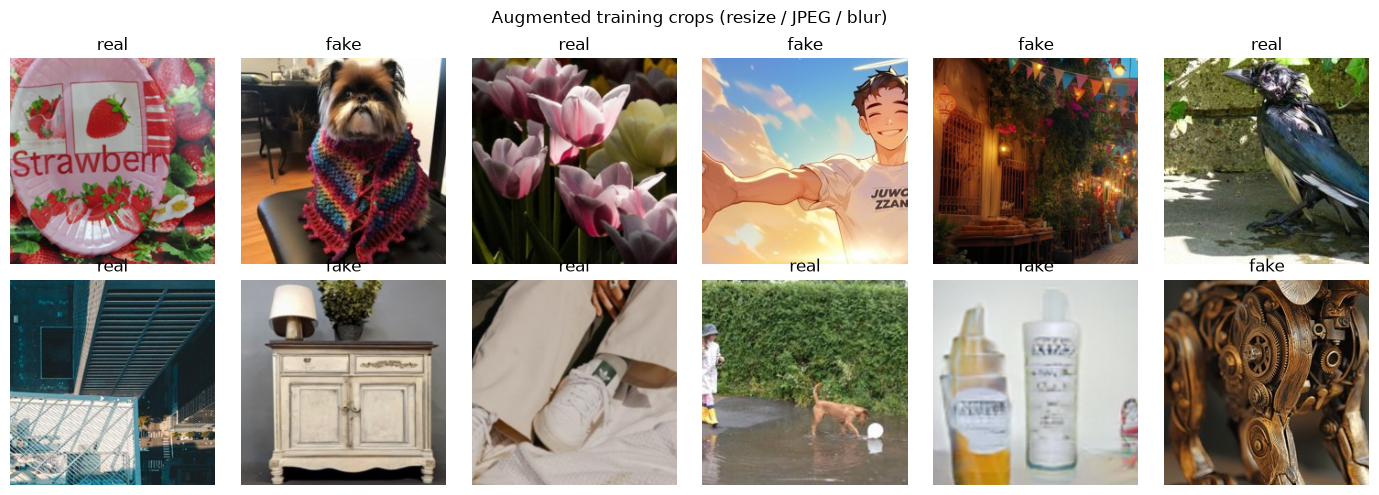

In [8]:
norm = [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
blur = transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 1.0))], p=0.2)
robust_crop = transforms.Compose([RandomRescale(), RandomJPEG(), blur,
                                  transforms.RandomCrop(224, pad_if_needed=True, padding_mode="reflect"),
                                  transforms.RandomHorizontalFlip(), *norm])
robust_tiny = transforms.Compose([transforms.Resize(256), RandomJPEG(), blur, transforms.RandomCrop(224),
                                  transforms.RandomHorizontalFlip(), *norm])

aivr_tr = datasets.ImageFolder(SETS["aivr_train"][0], robust_crop)
aivr_ev = datasets.ImageFolder(SETS["aivr_train"][0], eval_tf("crop", IMAGENET_MEAN, IMAGENET_STD))
tiny_tr = datasets.ImageFolder(SETS["tiny_train"][0], robust_tiny)
tiny_ev = datasets.ImageFolder(SETS["tiny_train"][0], eval_tf("tiny", IMAGENET_MEAN, IMAGENET_STD))

rng = np.random.RandomState(SEED)
t_idx = rng.permutation(len(tiny_tr))
a_idx = rng.choice(len(aivr_tr), len(tiny_tr), replace=False)
nt, na = len(t_idx) // 10, len(a_idx) // 10
joint_train = ConcatDataset([Subset(tiny_tr, t_idx[nt:].tolist()), Subset(aivr_tr, a_idx[na:].tolist())])
joint_val = ConcatDataset([Subset(tiny_ev, t_idx[:nt].tolist()), Subset(aivr_ev, a_idx[:na].tolist())])
print(f"train {len(joint_train)} | val {len(joint_val)}")

# Show what the augmented training images look like
xb, yb = next(iter(DataLoader(joint_train, batch_size=12, shuffle=True)))
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, img, lab in zip(axes.flat, xb, yb):
    ax.imshow((img.permute(1, 2, 0).numpy() * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1))
    ax.set_title(CLASSES[lab]); ax.axis("off")
plt.suptitle("Augmented training crops (resize / JPEG / blur)"); plt.tight_layout(); plt.show()

In [9]:
def run_epoch(model, loader, criterion, optimizer=None, scaler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, seen = 0.0, 0, 0
    for x, y in tqdm(loader, leave=False, desc="train" if training else "val"):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(training), torch.amp.autocast("cuda"):
            out = model(x)
            loss = criterion(out, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        seen += y.size(0)
    return total_loss / seen, correct / seen

EPOCHS, PATIENCE, LR = 15, 3, 1e-4
torch.manual_seed(SEED)
model = load_resnet("resnet18_ai_vs_real.pth")
kw = dict(batch_size=BATCH_SIZE, num_workers=WORKERS, pin_memory=True, persistent_workers=WORKERS > 0)
train_loader = DataLoader(joint_train, shuffle=True, **kw)
val_loader = DataLoader(joint_val, shuffle=False, **kw)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")
criterion = nn.CrossEntropyLoss()

history, best_acc, best_epoch, best_state = [], 0.0, 0, None
for epoch in range(1, EPOCHS + 1):
    start = time.time()
    tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler)
    va_loss, va_acc = run_epoch(model, val_loader, criterion)
    scheduler.step()
    history.append(dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc, val_loss=va_loss, val_acc=va_acc))
    print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | {(time.time() - start) / 60:.1f} min")
    if va_acc > best_acc:
        best_acc, best_epoch, best_state = va_acc, epoch, copy.deepcopy(model.state_dict())
    elif epoch - best_epoch >= PATIENCE:
        print(f"early stopping (no improvement for {PATIENCE} epochs)")
        break
torch.save(best_state, MODELS / "resnet18_robust.pth")
(MODELS / "resnet18_robust_info.json").write_text(json.dumps(
    dict(init="resnet18_ai_vs_real.pth", lr=LR, best_epoch=best_epoch, best_val_acc=best_acc, history=history), indent=2))
print(f"best val acc {best_acc:.4f} at epoch {best_epoch} -> saved models/resnet18_robust.pth")
del train_loader, val_loader; torch.cuda.empty_cache()

train:   0%|          | 0/788 [00:08<?, ?it/s]

val:   0%|          | 0/88 [00:08<?, ?it/s]

epoch  1 | train loss 0.4215 acc 0.8051 | val loss 0.3343 acc 0.8514 | 7.7 min


train:   0%|          | 0/788 [00:00<?, ?it/s]

val:   0%|          | 0/88 [00:00<?, ?it/s]

...

val:   0%|          | 0/88 [00:00<?, ?it/s]

epoch 10 | train loss 0.1614 acc 0.9347 | val loss 0.2596 acc 0.9023 | 6.6 min


train:   0%|          | 0/788 [00:00<?, ?it/s]

val:   0%|          | 0/88 [00:00<?, ?it/s]

epoch 11 | train loss 0.1465 acc 0.9420 | val loss 0.2604 acc 0.9071 | 6.2 min
early stopping (no improvement for 3 epochs)
best val acc 0.9071 at epoch 8 -> saved models/resnet18_robust.pth


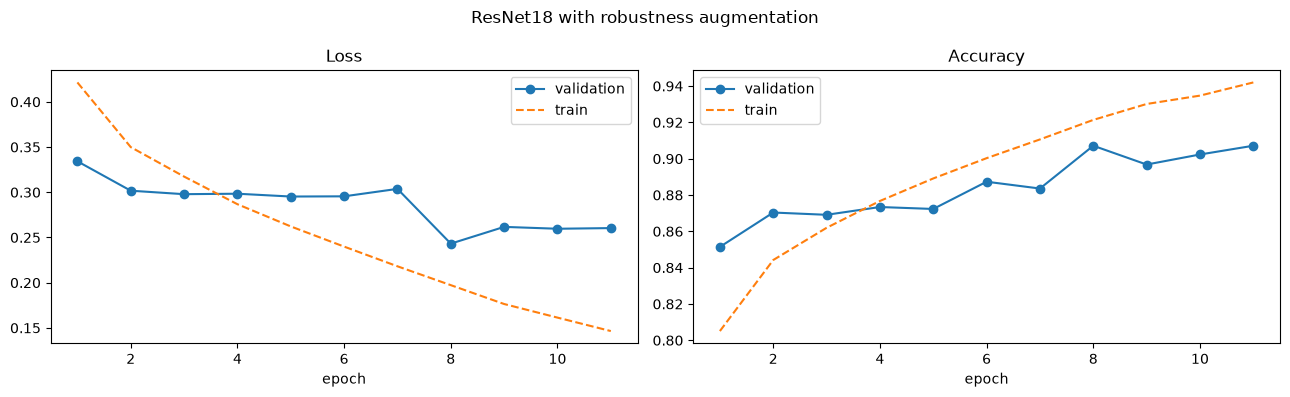

aivr_test:   0%|          | 0/94 [00:23<?, ?it/s]

tiny_val:   0%|          | 0/55 [00:28<?, ?it/s]

misinfo:   0%|          | 0/63 [00:07<?, ?it/s]

,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
ResNet18 + robust augmentation,0.924,0.9768,0.8779,0.9512,0.7272,0.8302,0.8278,0.6266


In [10]:
ep = [h["epoch"] for h in history]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(ep, [h["val_loss"] for h in history], marker="o", label="validation")
a1.plot(ep, [h["train_loss"] for h in history], "--", label="train")
a2.plot(ep, [h["val_acc"] for h in history], marker="o", label="validation")
a2.plot(ep, [h["train_acc"] for h in history], "--", label="train")
a1.set_title("Loss"); a2.set_title("Accuracy")
for a in (a1, a2):
    a.set_xlabel("epoch"); a.legend()
plt.suptitle("ResNet18 with robustness augmentation"); plt.tight_layout()
plt.savefig(OUTPUTS / "05_robust_curves.png", dpi=120); plt.show()

robust = load_resnet("resnet18_robust.pth")
display(score("ResNet18 + robust augmentation", resnet_probs(robust)))
del robust; torch.cuda.empty_cache()

## 5. Ensemble (zero-shot)
An **ensemble** averages the probabilities of several models; their mistakes partly cancel out.
The members are fixed in advance (not chosen by looking at Misinfo results).

In [11]:
members = ["CLIP ViT-L/14 + linear head", "DINOv2-L + linear head", "ResNet18 + robust augmentation"]
ens = {k: np.mean([PROBS[m][k] for m in members], axis=0) for k in ["aivr_test", "tiny_val", "misinfo"]}
display(score("Ensemble (CLIP + DINOv2 + robust ResNet18)", ens))

,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
Ensemble (CLIP + DINOv2 + robust ResNet18),0.9462,0.9879,0.9153,0.9743,0.8397,0.9101,0.8422,0.8372


## 6. Few-shot adaptation with 20% of Misinfo  ⚠ Misinfo is no longer fully unseen
In practice a deployed detector can be **adapted** with a small labelled sample from its target domain (here: a few
hundred news-style images per generator). The foundation-model classifiers are re-trained with the Misinfo **ADAPT 20%**
added (weighted to ~20% of the training signal) and tested on the **same TEST 80%** as everything else.
**Report this separately**, e.g. *"after adapting with 20% of Misinfo: X%"*.

In [12]:
FEW_HEADS = {}
for bname in BACKBONES:
    extra = (FEATS[bname]["misinfo"][MIS_ADAPT], LABELS["misinfo"][MIS_ADAPT])
    FEW_HEADS[bname] = train_head(bname, extra=extra)
    probs = {k: FEW_HEADS[bname].predict_proba(FEATS[bname][k])[:, 1] for k in ["aivr_test", "tiny_val", "misinfo"]}
    display(score(f"[few-shot 20%] {bname} + linear head", probs))

few = [f"[few-shot 20%] {b} + linear head" for b in BACKBONES]
ens_few = {k: np.mean([PROBS[m][k] for m in few], axis=0) for k in ["aivr_test", "tiny_val", "misinfo"]}
display(score("[few-shot 20%] Ensemble (CLIP + DINOv2)", ens_few))

  CLIP ViT-L/14 | C=0.01  validation acc 0.8814
  CLIP ViT-L/14 | C=0.1   validation acc 0.8842
  CLIP ViT-L/14 | C=1.0   validation acc 0.8917


,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
[few-shot 20%] CLIP ViT-L/14 + linear head,0.9022,0.9645,0.854,0.9305,0.9586,0.9923,0.9547,0.9625


  DINOv2-L | C=0.01  validation acc 0.8395
  DINOv2-L | C=0.1   validation acc 0.8388
  DINOv2-L | C=1.0   validation acc 0.8384


,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
[few-shot 20%] DINOv2-L + linear head,0.8548,0.9318,0.777,0.8613,0.9125,0.9703,0.9166,0.9084


,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
[few-shot 20%] Ensemble (CLIP + DINOv2),0.911,0.9685,0.8726,0.9385,0.9673,0.9933,0.96,0.9747


## 7. Final comparison

,AI vs Real acc,AI vs Real AUC,Tiny-GenImage acc,Tiny-GenImage AUC,Misinfo TEST acc,Misinfo TEST AUC,Misinfo fakes caught,Misinfo reals accepted
method,,,,,,,,
ResNet18 Stage 2 (current),0.9383,0.9854,0.9199,0.9757,0.7316,0.8622,0.8806,0.5825
CLIP ViT-L/14 + linear head,0.9044,0.9681,0.8619,0.9385,0.8222,0.8961,0.8109,0.8334
DINOv2-L + linear head,0.8662,0.9404,0.7941,0.8742,0.7306,0.8024,0.6869,0.7744
ResNet18 + robust augmentation,0.9240,0.9768,0.8779,0.9512,0.7272,0.8302,0.8278,0.6266
Ensemble (CLIP + DINOv2 + robust ResNet18),0.9462,0.9879,0.9153,0.9743,0.8397,0.9101,0.8422,0.8372
[few-shot 20%] CLIP ViT-L/14 + linear head,0.9022,0.9645,0.8540,0.9305,0.9586,0.9923,0.9547,0.9625
[few-shot 20%] DINOv2-L + linear head,0.8548,0.9318,0.7770,0.8613,0.9125,0.9703,0.9166,0.9084
[few-shot 20%] Ensemble (CLIP + DINOv2),0.9110,0.9685,0.8726,0.9385,0.9673,0.9933,0.9600,0.9747


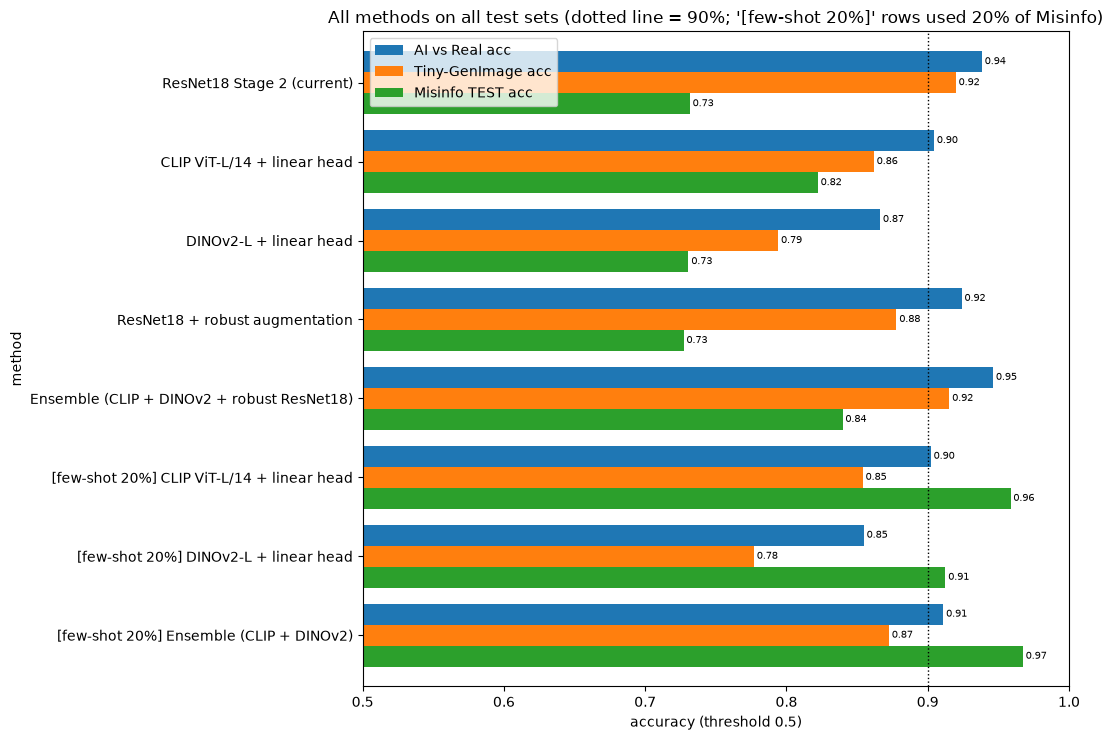

In [13]:
res = pd.DataFrame(RESULTS).set_index("method")
display(res.round(4))
res.to_csv(OUTPUTS / "05_comparison.csv")

cols = ["AI vs Real acc", "Tiny-GenImage acc", "Misinfo TEST acc"]
ax = res[cols].plot.barh(figsize=(11, 0.75 * len(res) + 1.5), xlim=(0.5, 1.0), width=0.8)
ax.axvline(0.9, color="k", ls=":", lw=1)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=2)
ax.invert_yaxis(); ax.set_xlabel("accuracy (threshold 0.5)")
ax.set_title("All methods on all test sets (dotted line = 90%; '[few-shot 20%]' rows used 20% of Misinfo)")
plt.tight_layout(); plt.savefig(OUTPUTS / "05_comparison.png", dpi=120); plt.show()


Ensemble (CLIP + DINOv2 + robust ResNet18)  (Misinfo TEST accuracy 83.97%)


,fakes caught,reals accepted
generator,,
FLUX1-dev,0.975,0.841
PixArt-XL-2-1024-MS,0.994,0.846
SDXL1,0.831,0.826
imagen3,0.569,0.835



[few-shot 20%] Ensemble (CLIP + DINOv2)  (Misinfo TEST accuracy 96.73%)


,fakes caught,reals accepted
generator,,
FLUX1-dev,0.989,0.969
PixArt-XL-2-1024-MS,1.000,0.980
SDXL1,0.945,0.976
imagen3,0.906,0.974


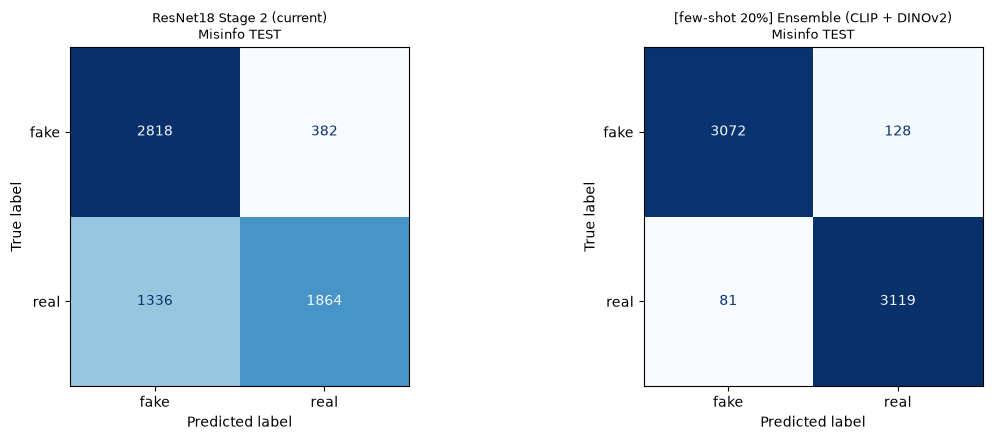

In [14]:
zero = res[~res.index.str.startswith("[few-shot")]
best_zero = zero["Misinfo TEST acc"].idxmax()
best_any = res["Misinfo TEST acc"].idxmax()
for name in dict.fromkeys([best_zero, best_any]):
    print(f"\n{name}  (Misinfo TEST accuracy {res.loc[name, 'Misinfo TEST acc']:.2%})")
    display(misinfo_per_generator(name))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["ResNet18 Stage 2 (current)", best_any]):
    p, y = PROBS[name]["misinfo"][MIS_TEST], LABELS["misinfo"][MIS_TEST]
    ConfusionMatrixDisplay(confusion_matrix(y, (p >= 0.5).astype(int)), display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{name}\nMisinfo TEST", fontsize=9)
plt.tight_layout(); plt.savefig(OUTPUTS / "05_confusion_before_after.png", dpi=120); plt.show()

## 8. Save the classifiers

In [15]:
for bname, cfg in BACKBONES.items():
    joblib.dump(HEADS[bname], MODELS / f"{cfg['slug']}_head.joblib")
    joblib.dump(FEW_HEADS[bname], MODELS / f"{cfg['slug']}_head_fewshot20.joblib")
print("saved:", sorted(p.name for p in MODELS.glob("*.joblib")))

saved: ['clip_vitl14_head.joblib', 'clip_vitl14_head_fewshot20.joblib', 'dinov2_l_head.joblib', 'dinov2_l_head_fewshot20.joblib']


## 9. How to report these results
- **Zero-shot (honest "unseen" number):** the best method among sections 1–5. Misinfo was never used.
- **Few-shot (section 6):** report as *"after adapting with 20% of Misinfo, tested on the remaining 80%"*.
- Always give **both** numbers and say which is which. Claiming the few-shot number as "unseen" would be wrong.
- The diagnosis plot (section 1) explains why the threshold alone could not fix the problem.

**Trade-off for the app:** the foundation models are much bigger than ResNet18 (CLIP ViT-L ≈ 300 M parameters vs 11 M),
so they are slower on CPU, and Grad-CAM as implemented in notebook 04 works on ResNet18 only (LIME works on any model).